### Data Profiling

##### Importing Libraries and Loading Data

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import json

In [2]:
df = pd.read_parquet('../data/raw/applications.parquet')

In [3]:
df.head(5)

,lpa_name,uprn,development_type,last_updated,decision,application_type,postcode,decision_process,description,borough,...,appeal_status,valid_date,url_planning_app,lpa_app_no,centroid,appeal_decision_date,appeal_decision,id,status,application_details
0,Hounslow,NaN,NaN,2022-09-05T11:00:25.707Z,Approved,All Other,NaN,NaN,Details of Condition 4 (Waste and Recycle) Con...,Hounslow,...,NaN,29/03/2022,NaN,00249/R/O/44/PA1(4-6),"{""lon"": -7.55716, ""lat"": 49.766807}",NaN,NaN,Hounslow-00249_R_O_44_PA1(4-6),Approved,NaN
1,Islington,NaN,00 Not Required,2022-02-03T10:12:50.738Z,NaN,All Other,NaN,NaN,NaN,Islington,...,NaN,NaN,NaN,P2022/0154/TRE,"{""lon"": ""-0.0929208"", ""lat"": ""51.5478906""}",NaN,NaN,Islington-P2022_0154_TRE,NaN,"{""site_area"": 0.039}"
2,Hounslow,NaN,NaN,2024-12-13T14:48:57.496Z,Opinion Issued,All Other,TW8 0NX,NaN,SIDE EXTENSION & RE STUDIO,Hounslow,...,NaN,03/10/2019,NaN,01122/22/P1,"{""lon"": -0.303379, ""lat"": 51.488912}",NaN,NaN,Hounslow-01122_22_P1_,Opinion Issued,NaN
3,Islington,5300085709,NaN,2025-03-19T11:34:42.196+00:00,NaN,All Other,EC1V 4JJ,NaN,"Work to be carried out at St Johns Square, Cle...",Islington,...,NaN,26/02/2025,NaN,P2025/0550/TRE,"{""lon"": -0.103124, ""lat"": 51.523063}",NaN,NaN,Islington-P2025_0550_TRE,Application Under Consideration,NaN
4,Islington,10093625150,NaN,2025-03-28T00:00:09.004Z,NaN,All Other,NaN,NaN,Internal adaptation of a space at lower ground...,Islington,...,NaN,27/01/2025,NaN,P2025/0132/LBC,"{""lon"": -0.105958, ""lat"": 51.522498}",NaN,NaN,Islington-P2025_0132_LBC,Called in by Secretary of State,NaN


In [4]:
df.shape

(1303796, 24)

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1303796 entries, 0 to 1303795
Data columns (total 24 columns):
 #   Column                 Non-Null Count    Dtype
---  ------                 --------------    -----
 0   lpa_name               1303796 non-null  str  
 1   uprn                   1102298 non-null  str  
 2   development_type       532356 non-null   str  
 3   last_updated           1303796 non-null  str  
 4   decision               1213373 non-null  str  
 5   application_type       1303796 non-null  str  
 6   postcode               1007778 non-null  str  
 7   decision_process       926316 non-null   str  
 8   description            1286535 non-null  str  
 9   borough                1299027 non-null  str  
 10  ward                   1220453 non-null  str  
 11  application_type_full  765558 non-null   str  
 12  decision_agency        453077 non-null   str  
 13  decision_date          1229798 non-null  str  
 14  appeal_status          5694 non-null     str  
 15  valid_dat

In [6]:
# Is 'id' different on every row? If yes, it's a primary key

print(df['id'].is_unique)

True


In [7]:
# Is the council's own reference unique on its own?

print(df['lpa_app_no'].is_unique)

False


In [8]:
# How many rows repeat the same authority + reference pair?

print(df.duplicated(['lpa_name', 'lpa_app_no']).sum())

0


##### Missing Values

In [9]:
placeholders = ['', 'NULL', 'Unknown', 'Missing', 'No description provided by LDMS']

In [10]:
# % of real nulls and % of placeholder text, per column

missing = pd.DataFrame({
    'null_%': df.isna().mean() * 100,
    'placeholder_%': df.isin(placeholders).mean() * 100,
})

In [11]:
# Add them up and sort, worst first

missing['total_%'] = missing['null_%'] + missing['placeholder_%']
missing.round(1).sort_values('total_%', ascending=False)

,null_%,placeholder_%,total_%
appeal_status,99.6,0.0,99.6
appeal_decision_date,97.1,0.0,97.1
appeal_decision,96.7,0.0,96.7
decision_agency,65.2,0.0,65.2
url_planning_app,62.7,0.0,62.8
development_type,59.2,0.4,59.5
application_type_full,41.3,0.0,41.3
decision_process,29.0,0.3,29.2
postcode,22.7,3.5,26.2
application_details,24.0,0.0,24.0


In [12]:
# Distinct values per column

df.nunique().sort_values()

application_type               3
appeal_status                 11
decision_agency               11
decision_process              18
appeal_decision               22
lpa_name                      36
application_type_full         72
decision                     118
status                       119
borough                      155
development_type             201
ward                        2261
appeal_decision_date        7293
decision_date              13259
valid_date                 13370
application_details        85476
postcode                  115529
url_planning_app          476548
uprn                      495401
centroid                  682384
description              1106164
last_updated             1156675
lpa_app_no               1250896
id                       1303796
dtype: int64

In [13]:
 # The 10 rarest 'borough' labels

df['borough'].value_counts().tail(10)

borough
Raynes Park          1
REDBRIDGE            1
Hawley Wharf         1
SHOREDITCH           1
Kenton               1
Dalston              1
Chingford            1
28 Jamestown Road    1
Harrow Road          1
Whitton              1
Name: count, dtype: int64

##### Locations

In [14]:
# Turn each centroid's JSON text into numbers: one 'lon' and one 'lat' column

coords = pd.DataFrame(df['centroid'].map(json.loads).tolist()).astype(float)

In [15]:
# True if the point falls inside a box around Greater London

in_london = coords['lon'].between(-0.52, 0.34) & coords['lat'].between(51.28, 51.70)

In [16]:
# How many points fall outside London?

print((~in_london).sum())

115973


In [17]:
# The most common points outside London

coords[~in_london].round(2).value_counts().head(3)

lon     lat  
-7.56   49.77    114730
-15.95  90.00      1024
-6.98   51.35        23
Name: count, dtype: int64

##### Dates

In [18]:
# Parse the UK-format date text (day/month/year) into real dates; bad text becomes NaT

df['valid_dt'] = pd.to_datetime(df['valid_date'], format='%d/%m/%Y', errors='coerce')
df['decision_dt'] = pd.to_datetime(df['decision_date'], format='%d/%m/%Y', errors='coerce')
df['valid_year'] = df['valid_dt'].dt.year.astype('Int64')

In [19]:
# The snapshot date = the newest sync timestamp in the data

snapshot = pd.to_datetime(df['last_updated'], utc=True).max().tz_localize(None)
print(snapshot)

2026-11-11 03:25:41.822000


In [20]:
# Earliest and latest valid dates

print(df['valid_dt'].min(), df['valid_dt'].max())

1900-01-01 00:00:00 3034-08-30 00:00:00


In [21]:
# How many applications claim to be from after the snapshot? (impossible)

print((df['valid_dt'] > snapshot).sum())

32


In [22]:
# Days from valid to decision: median, and how many are negative (impossible)

lag_days = (df['decision_dt'] - df['valid_dt']).dt.days
print(lag_days.median())
print((lag_days < 0).sum())

56.0
876


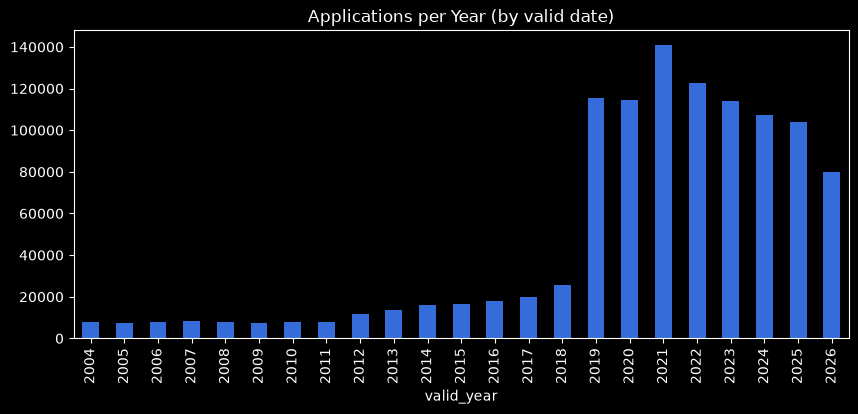

In [23]:
# Count applications per year and plot from 2004

per_year = df['valid_year'].value_counts().sort_index()
per_year.loc[2004:2026].plot(kind='bar', figsize=(10, 4), title='Applications per Year (by valid date)')
plt.show()

In [24]:
# Table of applications: one row per authority, one column per year (2015-2026)

coverage = pd.crosstab(df['lpa_name'], df['valid_year']).loc[:, 2015:2026]

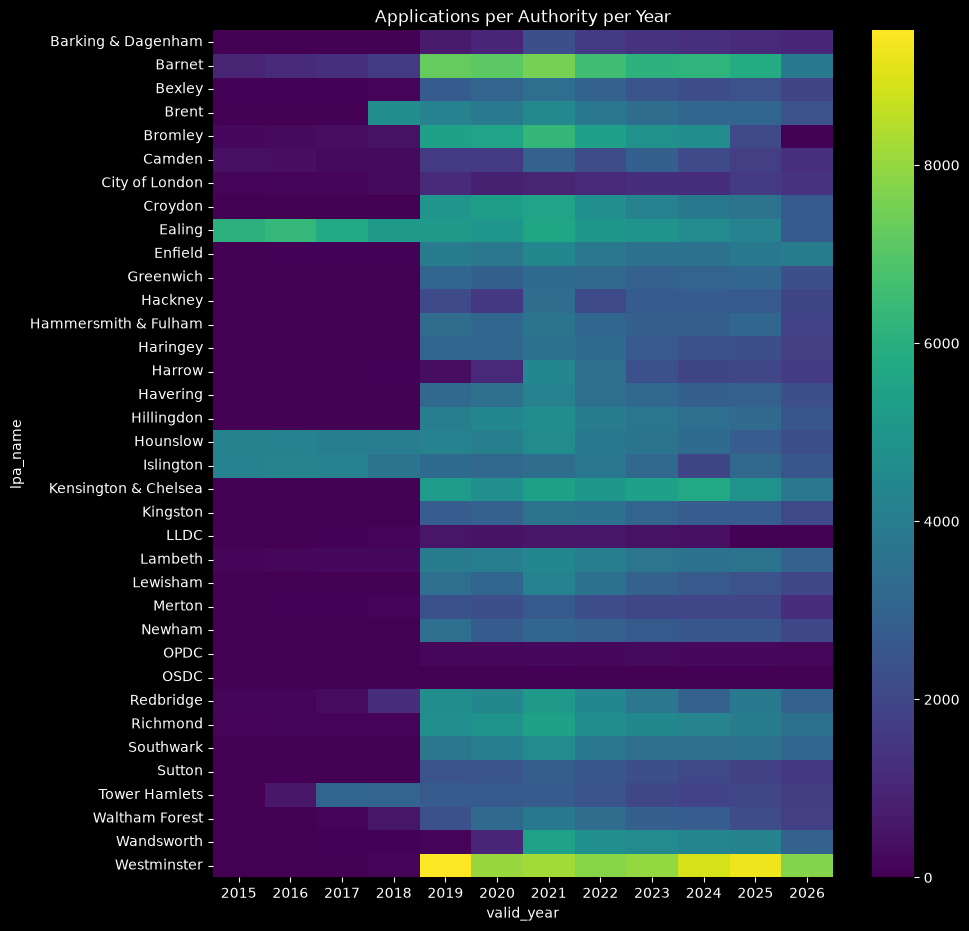

In [25]:
# Colour each cell by its count

plt.figure(figsize=(10, 11))
sns.heatmap(coverage, cmap='viridis')
plt.title('Applications per Authority per Year')
plt.show()

##### Outcomes

In [26]:
# How many different decision spellings, and the 15 most common

print(df["decision"].nunique())
df["decision"].value_counts().head(15)

118


decision
Approved                                   861465
Refused                                    156277
Withdrawn                                   62335
No Objection to Proposal (OBS only)         30465
Not Required                                29077
Comment Issued                              27893
Closed                                      13801
Unknown                                      5618
REFUSED                                      5081
Opinion Issued                               3255
PDV                                          2540
REF                                          2173
Approve                                      1919
Split Decision                               1813
Objection Raised to Proposal (OBS only)      1618
Name: count, dtype: int64

In [27]:
# Rows whose decision and status are both among the main values

main = ['Approved', 'Refused', 'Withdrawn']
both = df[df['decision'].isin(main) & df['status'].isin(main + ['Completed', 'Lapsed'])]

In [28]:
# Cross-count decision (rows) against status (columns)

pd.crosstab(both['decision'], both['status'])

status,Approved,Completed,Lapsed,Refused,Withdrawn
decision,,,,,
Approved,643107,108622,40316,104,30
Refused,108,4297,551,116209,85
Withdrawn,28,25,27,0,42199


In [29]:
# What each council's short codes mean, judged by the status of the same applications

codes = df['decision'].isin(['PDV', 'PARG', 'REF', 'WDN', 'WTHDRW'])
pd.crosstab(df.loc[codes, 'decision'], df.loc[codes, 'status'])[['Approved', 'Completed', 'Refused', 'Withdrawn']]

status,Approved,Completed,Refused,Withdrawn
decision,,,,
PARG,118,5,0,0
PDV,2453,51,0,0
REF,0,5,1803,0
WDN,0,0,0,888
WTHDRW,0,0,0,88


In [30]:
# True where a real decision has been recorded

has_decision = df['decision'].notna() & ~df['decision'].isin(placeholders)

In [31]:
# Applications submitted in the 2 years before the snapshot

recent = df['valid_dt'].between(snapshot - pd.DateOffset(years=2), snapshot)

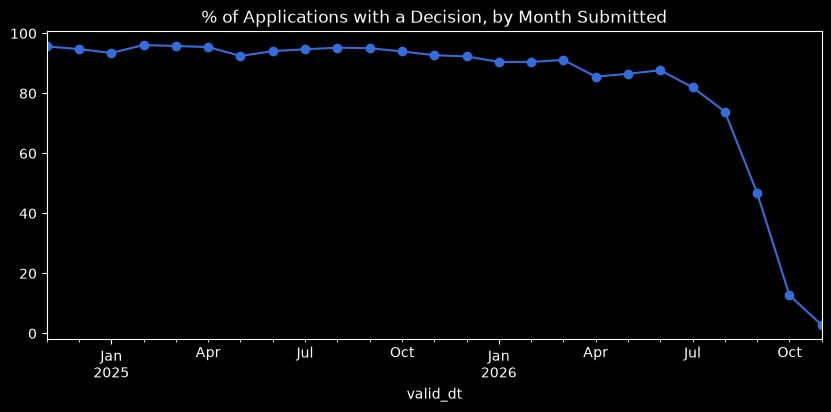

In [32]:
# % with a decision, per month submitted

pct = has_decision[recent].groupby(df.loc[recent, 'valid_dt'].dt.to_period('M')).mean() * 100
pct.plot(figsize=(10, 4), marker='o', title='% of Applications with a Decision, by Month Submitted')
plt.show()

In [33]:
# The modelling window: submitted from 2019 up to the snapshot

since_2019 = df[df['valid_dt'].between('2019-01-01', snapshot)]
print(len(since_2019))

899237


In [34]:
# Share of Approved vs Refused among those two outcomes

since_2019.loc[since_2019['decision'].isin(['Approved', 'Refused']), 'decision'].value_counts(normalize=True).round(3)

decision
Approved    0.824
Refused     0.176
Name: proportion, dtype: float64

##### Description Text

In [35]:
# Length of every description, in characters

length = since_2019['description'].str.len()
print(length.describe().round(0))

count    885763.0
mean        199.0
std         207.0
min           0.0
25%          85.0
50%         139.0
75%         233.0
max        4910.0
Name: description, dtype: float64


In [36]:
# How many are too short to say anything (under 20 characters)?

print((length < 20).sum())

6098


In [37]:
# The short descriptions are still informative, so they stay

since_2019.loc[length < 20, 'description'].value_counts().head(8)

description
Vehicular access.      104
New front porch         84
Rear dormer.            63
Vehicular access        52
Prune as specified      50
New shopfront           31
Porch to front          30
Rear roof extension     30
Name: count, dtype: int64

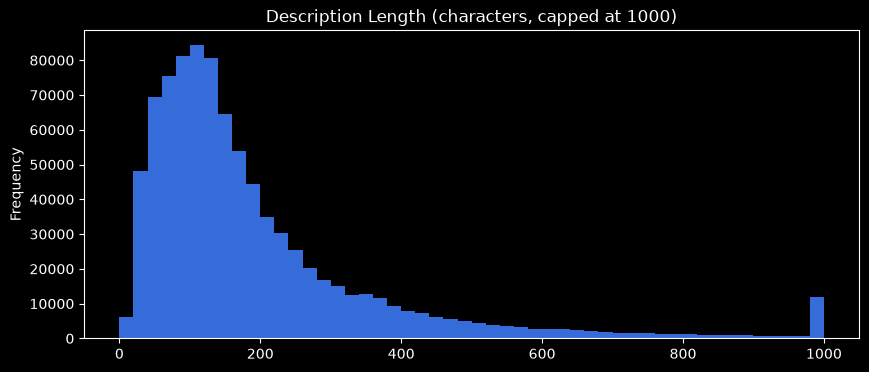

In [38]:
# Histogram of lengths, very long ones grouped at 1000

length.clip(upper=1000).plot(kind='hist', bins=50, figsize=(10, 4), title='Description Length (characters, capped at 1000)')
plt.show()

In [39]:
# Normalise text so trivial differences don't hide duplicates

text = since_2019['description'].dropna().str.lower().str.strip().str.rstrip('.')

In [40]:
# % of descriptions whose exact text appears more than once

print(text.duplicated(keep=False).mean() * 100)

20.938106468660354


In [41]:
# The most repeated descriptions

text.value_counts().head(5)

description
single storey rear extension                      7634
erection of a single storey rear extension        3432
erection of single storey rear extension          1619
construction of a single storey rear extension    1085
single storey side extension                       928
Name: count, dtype: int64

In [42]:
# % of rows with each candidate category label filled in, per authority

labels = since_2019.groupby('lpa_name')[['application_type_full', 'development_type']].agg(
    lambda s: s.notna().mean() * 100)
labels.round(0).sort_values('development_type')

,application_type_full,development_type
lpa_name,,
Barnet,68.0,0.0
Bexley,69.0,0.0
City of London,71.0,0.0
Bromley,61.0,0.0
Croydon,71.0,0.0
Greenwich,73.0,0.0
Havering,68.0,0.0
LLDC,44.0,0.0
Southwark,54.0,0.0


##### Application Form Facts

In [43]:
# Parse the application-form facts (stored as JSON text) into columns, keeping each row's label

details = since_2019['application_details'].dropna()
form = pd.json_normalize(details.map(json.loads).tolist()).set_index(details.index)
form.columns

Index(['site_area', 'residential_details.total_no_proposed_residential_units',
       'residential_details.total_no_existing_residential_units',
       'building_details'],
      dtype='str')

In [44]:
# Proposed homes: how many filled in, how many zero, how many positive

units = form['residential_details.total_no_proposed_residential_units']
print(units.notna().sum(), (units == 0).sum(), (units > 0).sum())

222549 175323 47226


In [45]:
# Tallest building per application (some storeys arrive as text, so convert to numbers)

buildings = form['building_details'].explode().dropna()
storeys = pd.to_numeric(buildings.map(lambda b: b.get('no_storeys')), errors='coerce')
storeys = storeys.groupby(level=0).max()
print((storeys > 0).sum(), storeys.max())

46776 909.0


In [46]:
# Site area in hectares; anything bigger than London itself (~157,000 ha) is an entry error

site = form['site_area']
print(site.notna().sum(), (site > 157_000).sum(), (site > 100).sum())

666055 13 7128


In [47]:
# Sites over 100 ha per authority: concentrated in a few councils, so likely square metres

(site > 100).groupby(since_2019['lpa_name']).sum().sort_values(ascending=False).head(5)

lpa_name
Kingston    2016
Enfield     1744
Hackney      764
Bexley       659
Sutton       360
Name: site_area, dtype: int64

##### Findings and Decisions

**Data facts**
- 1,303,796 applications, 24 columns, snapshot taken 2026-11-11.
- `id` is the primary key; `lpa_name` + `lpa_app_no` is also unique.
- 36 authorities: 32 boroughs, City of London, LLDC, OPDC and OSDC (Oxford Street, new in 2026).
- Most authorities only start reporting in 2019 (coverage heatmap).
- Median time from valid date to decision: 56 days.
- Since 2019: 899,237 applications. After cleaning: 589,391 approved, 132,458 refused (81.6% approved).
- 20.9% of descriptions are exact repeats.
- Form facts (since 2019): 694,969 applications have form data; 47,226 propose at least one home; 46,776 give storeys.

**Decisions (implemented in `src/planscope/clean.py`)**
1. **Authority:** use `lpa_name` (36 clean values). Drop `borough` (155 messy labels) and `ward`.
2. **Text:** collapse whitespace and control characters; convert placeholders ('', 'NULL', 'Unknown', 'Missing', 'Not yet decided', 'No description provided by LDMS') to nulls.
3. **Dates:** parse as day/month/year. Keep decision dates only between the valid date and the snapshot.
4. **Locations:** parse `centroid` into `lon`/`lat`. Null any point outside the London bounding box (115,973 in the raw data).
5. **Window:** keep applications submitted from 2019-01-01 to the snapshot (899,237 rows).
6. **Outcome:** map decisions to APPROVED / REFUSED / WITHDRAWN / OTHER, case-insensitively. Council codes are mapped only where the status column confirms them (Ealing's PDV/PARG → approved, REF → refused, WDN/WTHDRW → withdrawn). No decision → null. Decision route: keep Delegated/Committee; null the unexplained numeric codes.
7. **Right-censoring:** recent months are mostly undecided (Sep 2026: 47%, Oct: 13%), so test the outcome model only on applications old enough to have a decision.
8. **Imbalance:** about 82/18 approved/refused, so judge models with PR-AUC, never accuracy.
9. **Text tasks:** keep short descriptions; they're informative ("New front porch", "Rear dormer"). Deduplicate before any train/test split (done in the modelling code, not in cleaning).
10. **Category:** group the 72 `application_type_full` values into 9 categories with ordered keyword rules (only 123 rows fall into "other"). It's the classifier's label, not `development_type` (empty for 15 of 36 authorities).
11. **Form facts:** storeys outside 1–100 become null (0 means blank; one 909 typo). Site areas outside 0–100 ha become null: the over-100 values cluster in Kingston, Enfield, Hackney and Bexley (likely square metres), and converting them would invent data whenever the guess is wrong.
12. **Drop:** appeal fields (97–100% empty), `status`, `development_type`, `decision_agency`, `postcode`.